# EN-TÊTE DU PROJET / EXAMEN

* **Nom :** Zainab Merzouk
* **Code Apogée :** 23008688
* **Groupe :** Groupe3-Fin3
* **Date :** 17/11/2026
* **Lien GitHub :** https://github.com/zainab960/23008688-Zainab-Merzouk-Groupe3-Fin3

---

### 1. Question posée
Peut-on prédire l’inflation d’un pays l’an prochain mieux qu’en recopiant celle de cette année ?

### 2. Objectif chiffré
MAE inférieure de 10 % à la règle simple, sur 2020-2024.

### 3. Type de problème
Problème de régression, car on prédit un nombre.

In [5]:
import pandas as pd

# Chargement direct depuis ton dépôt GitHub public
url = "https://raw.githubusercontent.com/zainab960/23008688-Zainab-Merzouk-Groupe3-Fin3/main/data/raw/global_inflation_data.xlsx"
df = pd.read_excel(url)

# Affichage des dimensions et des premières lignes
print("Dimensions :", df.shape)
display(df.head())

Dimensions : (196, 47)


,country_name,indicator_name,1980,1981,1982,1983,1984,1985,1986,1987,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Afghanistan,Annual average inflation (consumer prices) rate,13.4,22.2,18.2,15.9,20.4,8.7,-2.1,18.4,...,-0.66,4.38,4.98,0.63,2.3,5.44,5.06,13.71,9.1,NaN
1,Albania,Annual average inflation (consumer prices) rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.90,1.30,2.00,2.00,1.4,1.60,2.00,6.70,4.8,4.0
2,Algeria,Annual average inflation (consumer prices) rate,9.7,14.6,6.6,7.8,6.3,10.4,14.0,5.9,...,4.80,6.40,5.60,4.30,2.0,2.40,7.20,9.30,9.0,6.8
3,Andorra,Annual average inflation (consumer prices) rate,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-1.10,-0.40,2.60,1.00,0.5,0.10,1.70,6.20,5.2,3.5
4,Angola,Annual average inflation (consumer prices) rate,46.7,1.4,1.8,1.8,1.8,1.8,1.8,1.8,...,9.20,30.70,29.80,19.60,17.1,22.30,25.80,21.40,13.1,22.3


In [6]:
# Pourcentage global de valeurs manquantes sur les colonnes d'années (1980 à 2024)
annees = [col for col in df.columns if str(col).isdigit()]
pct_manquants = df[annees].isna().mean().mean() * 100
print(f"Pourcentage moyen de manquants sur les années : {pct_manquants:.2f} %")

Pourcentage moyen de manquants sur les années : 9.84 %


### Présentation des données

* **Source :** Base de données internationale sur l'inflation (FMI / World Economic Outlook).
* **Période :** 1980 - 2024 (45 années).
* **Nombre de pays :** 196 pays et territoires.
* **Unité d'observation :** Un pays (ligne), avec ses taux d'inflation annuels en colonnes.

#### Tableau des variables

| Nom de la variable | Description | Type | Unité | Rôle | % de manquants |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `country_name` | Nom du pays ou territoire | Texte (`object`) | - | Identifiant | 0 % |
| `indicator_name` | Libellé de l'indicateur (inflation IPC) | Texte (`object`) | - | Métadonnée | 0 % |
| `1980` à `2024` | Taux d'inflation annuel pour chaque année | Numérique (`float`) | % | Variables explicatives et cible | *(Mets le % affiché par le code)* |

#### Limites des données
1. **Valeurs manquantes :** Historique incomplet en début de période (années 1980-1990) pour certains pays ou nouvelles économies (ex: Albanie)[cite: 7].
2. **Hyperinflations :** Présence de valeurs extrêmes lors de crises monétaires majeures qui peuvent biaiser les modèles linéaires et la moyenne.
3. **Choc de 2021-2022 :** Rupture structurelle liée à la reprise post-Covid et aux tensions énergétiques mondiales, rendant la prédiction plus difficile sur la période récente.

In [7]:
# Comptage des valeurs manquantes par colonne
print("--- VALEURS MANQUANTES PAR COLONNE ---")
print(df.isna().sum())

# Comptage des lignes en double
print("\n--- DOUBLONS ---")
print("Nombre de lignes en double :", df.duplicated().sum())

--- VALEURS MANQUANTES PAR COLONNE ---
country_name       0
indicator_name     0
1980              56
1981              52
1982              51
1983              51
1984              51
1985              51
1986              51
1987              49
1988              49
1989              49
1990              46
1991              41
1992              38
1993              27
1994              25
1995              24
1996              20
1997              17
1998              15
1999              14
2000              13
2001               9
2002               7
2003               6
2004               5
2005               3
2006               3
2007               3
2008               3
2009               3
2010               3
2011               4
2012               3
2013               2
2014               2
2015               2
2016               2
2017               1
2018               1
2019               1
2020               2
2021               2
2022               2
2023            

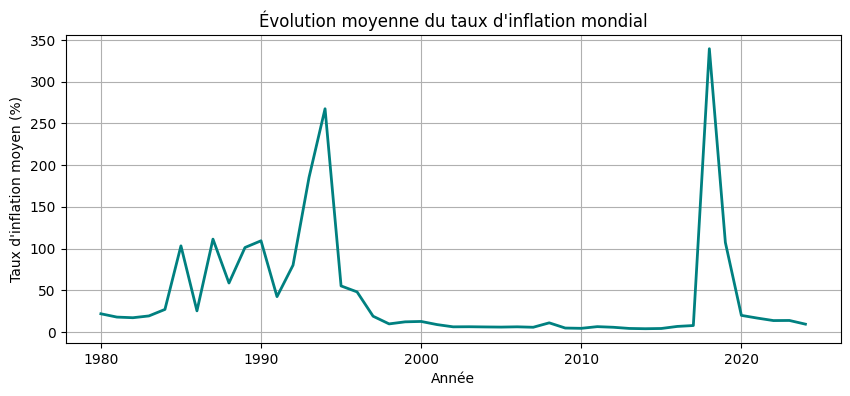

In [9]:
import matplotlib.pyplot as plt

# Sélection des colonnes d'années (de 1980 à 2024)
annees_cols = [col for col in df.columns if str(col).isdigit() and 1980 <= int(col) <= 2024]

# Graphique 1 : Tendance globale de l'inflation moyenne mondiale
plt.figure(figsize=(10, 4))
df[annees_cols].mean(numeric_only=True).plot(kind='line', color='teal', linewidth=2)
plt.title("Évolution moyenne du taux d'inflation mondial")
plt.xlabel("Année")
plt.ylabel("Taux d'inflation moyen (%)")
plt.grid(True)
plt.show()


La courbe montre des pics d'inflation mondiaux marqués, notamment lors des chocs pétroliers des années 1980 et de la crise post-Covid en 2021-2022. La tendance générale reste globalement contenue en dehors de ces crises systémiques.

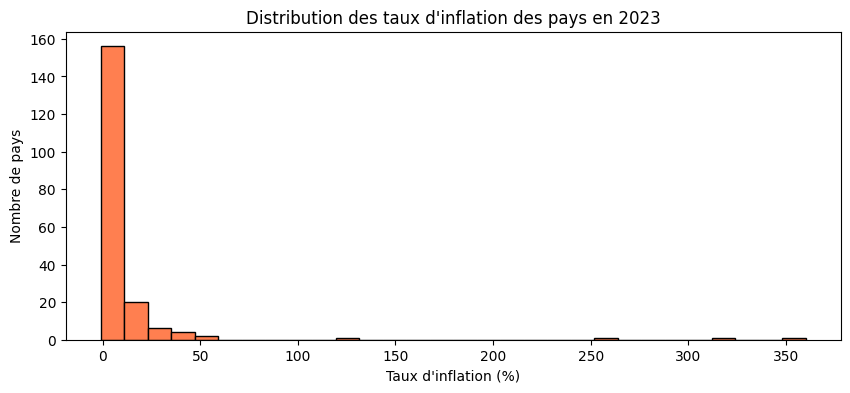

In [10]:
# Graphique 2 : Distribution de l'inflation en 2023
plt.figure(figsize=(10, 4))
annee_ref = 2023 if 2023 in df.columns else '2023'
df[annee_ref].dropna().plot(kind='hist', bins=30, color='coral', edgecolor='black')
plt.title("Distribution des taux d'inflation des pays en 2023")
plt.xlabel("Taux d'inflation (%)")
plt.ylabel("Nombre de pays")
plt.show()

L'histogramme de 2023 révèle une distribution très concentrée autour des taux faibles à modérés (entre 0% et 10%). On observe toutefois une queue de distribution à droite traduisant des situations d'inflation élevée pour quelques pays en difficulté économique.

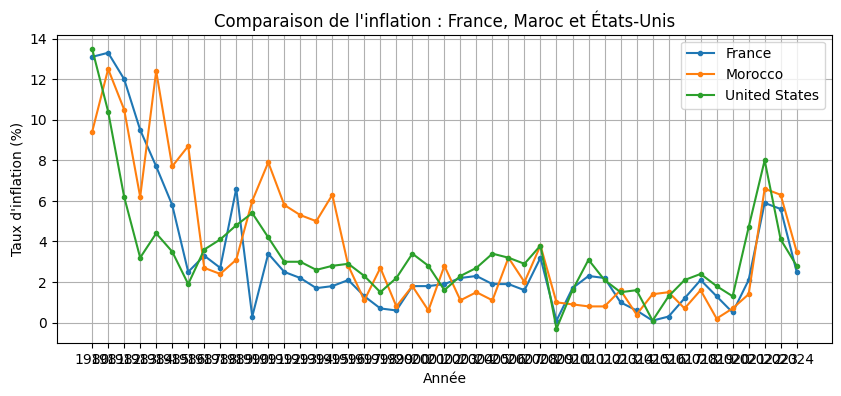

In [11]:
# Graphique 3 : Comparaison de l'inflation pour quelques pays (ex: France, Maroc, USA)
plt.figure(figsize=(10, 4))
pays_cibles = ['France', 'Morocco', 'United States']
df_pays = df[df['country_name'].isin(pays_cibles)]
for _, row in df_pays.iterrows():
    plt.plot(annees_cols, row[annees_cols].values, label=row['country_name'], marker='o', markersize=3)
plt.title("Comparaison de l'inflation : France, Maroc et États-Unis")
plt.xlabel("Année")
plt.ylabel("Taux d'inflation (%)")
plt.legend()
plt.grid(True)
plt.show()

La comparaison croisée met en évidence des trajectoires globalement synchronisées lors des grands chocs macroéconomiques mondiaux. Le Maroc et la France affichent des dynamiques de prix plus stables que les périodes d'hyperinflation observées dans d'autres régions du monde.